# LSEG FTSE Research

<table style="width:100%; table-layout:fixed; text-align:left;">
<thead>
<tr>
<th style="width:45%;">Title</th>
<th style="width:20%;">Authors</th>
<th style="width:7%;">Year</th>
<th style="width:13%;">Paper</th>
</tr>
</thead>
<tbody>
<tr>
<td>Fallen Angels in the US Credit Market: Characteristics, Historical Performance and Differences Between the Current Credit Cycle and Earlier Regimes</td>
<td>FTSE Russell</td>
<td>2019</td>
<td><a href="https://www.lseg.com/content/dam/ftse-russell/en_us/documents/research/fallen-angels-us-credit-market.pdf">Link</a></td>
</tr>
<tr>
<td>Are Fallen Angels still angelic performers? </td>
<td>Robin Marhsall</td>
<td>2025</td>
<td><a href="https://www.lseg.com/content/dam/ftse-russell/en_us/documents/research/are-fallen-angels-still-angelic-performers.pdf">Link</a></td>
</tr>
</tbody>
</table>

# Packages and Global Variables

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
res_path  = os.getcwd()
repo_path = os.path.abspath(os.path.join(res_path, ".."))
data_path = os.path.join(repo_path, "data")
raw_path  = os.path.join(data_path, "RawData")

In [3]:
sig_path = r"A:\GitHub\SignalTrader\src"
sys.path.append(sig_path)

from SignalFitter import SignalFitter

# *Fallen Angels in the US Credit Market: Characteristics, Historical Performance and Differences Between the Current Credit Cycle and Earlier Regimes*

In [4]:
cred_path   = os.path.join(raw_path, "PX.parquet")
df_cred_rtn = (pd
    .read_parquet(path = cred_path, engine = "pyarrow")
    .loc[lambda x: x.Price == "Adj Close"]
    .pivot(index = "date", columns = "ticker", values = "value")
    .pct_change()
    .reset_index()
    .melt(id_vars = "date")
    .dropna()
    .rename(columns = {
        "ticker": "cred_ticker",
        "value" : "cred_rtn"}))

In [5]:
eq_path   = os.path.join(raw_path, "EquityPX.parquet")
df_eq_rtn = (pd
    .read_parquet(path = eq_path, engine = "pyarrow")
    .loc[lambda x: x.Price == "Adj Close"]
    .pivot(index = "date", columns = "ticker", values = "value")
    .pct_change()
    .reset_index()
    .melt(id_vars = "date")
    .dropna()
    .rename(columns = {
        "ticker": "eq_ticker",
        "value" : "eq_rtn"}))

In [6]:
df_combined = (df_cred_rtn
    .merge(right = df_eq_rtn, how = "inner", on = ["date"])
    .assign(name = lambda x: x.eq_ticker + "-" + x.cred_ticker))

In [7]:
sg = (SignalFitter(
    rtn_col   = "cred_rtn",
    group_col = "name", 
    date_col  = "date"))

In [8]:
is_models = sg.fit_full_sample(df_combined, signal_col = "eq_rtn", vol_norm = False)

In [9]:
df_params = (sg
    .get_params(is_models)
    .loc[lambda x: x.variable != "const"]
    .drop(columns = ["nobs", "rsquared"])
    .assign(
        benchmark = lambda x: x.name.str.split("-").str[0],
        cred      = lambda x: x.name.str.split("-").str[1])
    .drop(columns = ["name", "variable"])
    .melt(id_vars = ["benchmark", "cred"]))

Below is a table of equity $\beta$ for each Credit ETF in the universe

In [10]:
(df_params
    .loc[lambda x: x.variable == "params"]
    .pivot(index = "cred", columns = "benchmark", values = "value")
    .apply(lambda x: np.round(x,3)))

benchmark,DIA,IWD,QQQ,SPY,VFMO,VFMV,VFQY,VFVA
cred,,,,,,,,
AGG,-0.004,-0.004,-0.001,-0.001,0.035,0.085,0.041,0.023
ANGL,0.322,0.334,0.230,0.323,0.251,0.459,0.318,0.260
FALN,0.346,0.362,0.242,0.349,0.247,0.463,0.315,0.256
HYG,0.377,0.365,0.291,0.376,0.251,0.455,0.318,0.258
JNK,0.353,0.353,0.274,0.354,0.250,0.454,0.319,0.259
LQD,0.069,0.062,0.052,0.074,0.114,0.222,0.135,0.097
SJNK,0.257,0.268,0.184,0.260,0.194,0.354,0.248,0.204
SPHY,0.250,0.262,0.184,0.257,0.211,0.388,0.271,0.221
USHY,0.321,0.339,0.233,0.328,0.234,0.426,0.298,0.241


We can then take the average credit $\beta$ per security

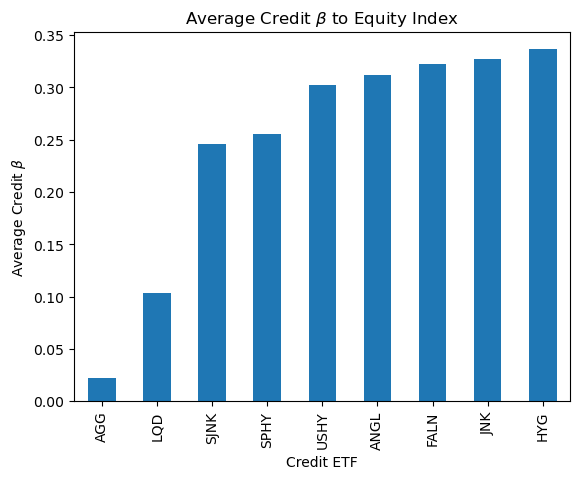

In [11]:
(df_params
    .loc[lambda x: x.variable == "params"]
    .drop(columns = ["variable", "benchmark"])
    .groupby("cred")
    .agg("mean")
    .sort_values("value")
    .plot(
        legend = False,
        kind   = "bar",
        ylabel = r"Average Credit $\beta$",
        title  = r"Average Credit $\beta$ to Equity Index",
        xlabel = "Credit ETF"))
plt.show()

In [12]:
(df_cred_rtn
    .drop(columns = ["date"])
    .rename(columns = {"cred_ticker": ""})
    .groupby("")
    ["cred_rtn"]
    .agg(["mean", "std"])
    .add_suffix("_val")
    .assign(
        sharpe = lambda x: x.mean_val / x.std_val * np.sqrt(252),
        mean_val = lambda x: x.mean_val * 252,
        std_val  = lambda x: x.std_val * np.sqrt(252))
    .apply(lambda x: np.round(x,3))
    .rename(columns = {
        "mean_val": "Ann. Rtn",
        "std_val" : "Ann. Vol",
        "sharpe"  : "Ann. Sharpe"})
    .sort_values("Ann. Sharpe"))

,Ann. Rtn,Ann. Vol,Ann. Sharpe
,,,
JNK,0.055,0.114,0.482
HYG,0.054,0.109,0.497
LQD,0.048,0.083,0.581
USHY,0.050,0.082,0.611
AGG,0.032,0.052,0.612
SPHY,0.051,0.078,0.661
FALN,0.067,0.089,0.757
ANGL,0.071,0.092,0.765
SJNK,0.048,0.059,0.821


# *Are Fallen Angels still angelic performers?*

In [13]:
df_corr = (df_cred_rtn
    .rename(columns = {"cred_ticker": ""})
    .pivot(index = "date", columns = "", values = "cred_rtn")
    .corr())

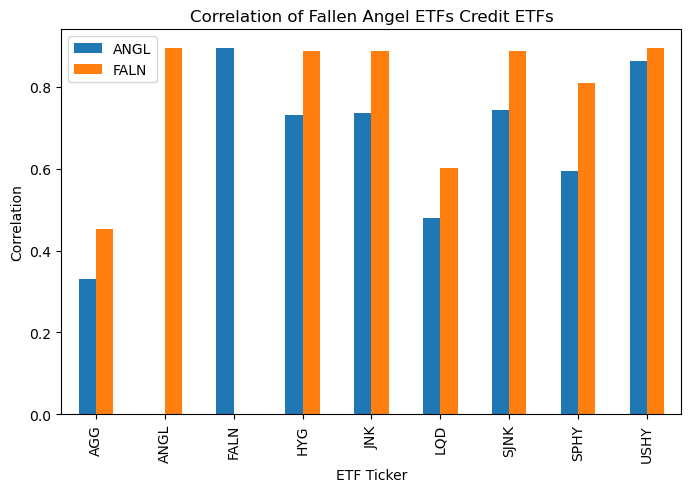

In [14]:
(df_corr
    [["ANGL", "FALN"]]
    .replace({1: np.nan})
    .sort_values("")
    .plot(
        figsize = (8,5),
        kind    = "bar",
        ylabel  = "Correlation",
        xlabel  = "ETF Ticker",
        title   = "Correlation of Fallen Angel ETFs Credit ETFs"))

plt.show()